# Run first dive: one subject, one run (*Le Petit Prince* MEG listening dataset)

A closer look at a single run (`sub-01`, run 01) of the listening dataset introduced
in the first-dive notebook: its events/channels metadata, MEG sidecar JSON, and
recording header, plus the session-level MEG files (calibration, crosstalk,
coordinate system) and the subject's anatomical MRI.

In [1]:
import sys
sys.path.append('..')

import gzip
import json
import struct
import wave

import pandas as pd
import mne

from config import LISTEN_DIR

subjects = sorted(p.name for p in LISTEN_DIR.glob('sub-*'))
meg_dir = LISTEN_DIR / subjects[0] / 'ses-01' / 'meg'
anat_dir = LISTEN_DIR / subjects[0] / 'ses-01' / 'anat'
run01_prefix = f"{subjects[0]}_ses-01_task-listen_run-01"

run01_prefix

'sub-01_ses-01_task-listen_run-01'

## Events and channels (one run)

`events.tsv` marks stimulus/task events within a run; `channels.tsv` describes each
recorded channel (MEG, EOG, ECG, etc.).


In [2]:
events = pd.read_csv(meg_dir / f"{run01_prefix}_events.tsv", sep='\t')
display(events.head())

channels = pd.read_csv(meg_dir / f"{run01_prefix}_channels.tsv", sep='\t')
channels['type'].value_counts()

,onset,duration,trial_type,stimulus
0,90.175,0.37,Word,lorsque
1,90.545,0.02,Word,j
2,90.656,0.23,Word,avais
3,91.056,0.25,Word,six
4,91.306,0.18,Word,ans


type
MEGGRADPLANAR    204
MEGMAG           102
TRIG              19
MISC              18
EOG                2
ECG                1
Name: count, dtype: int64

In [3]:
(events.iloc[-1]['onset'] + events.iloc[-1]['duration']-90.175)

np.float64(607.324)

In [4]:
channels.head()

,name,type,units,low_cutoff,high_cutoff,description,sampling_frequency,status,status_description
0,MEG0113,MEGGRADPLANAR,T/m,0.0,330.0,Planar Gradiometer,1000.0,good,NaN
1,MEG0112,MEGGRADPLANAR,T/m,0.0,330.0,Planar Gradiometer,1000.0,good,NaN
2,MEG0111,MEGMAG,T,0.0,330.0,Magnetometer,1000.0,good,NaN
3,MEG0122,MEGGRADPLANAR,T/m,0.0,330.0,Planar Gradiometer,1000.0,good,NaN
4,MEG0123,MEGGRADPLANAR,T/m,0.0,330.0,Planar Gradiometer,1000.0,good,NaN


## MEG sidecar metadata (one run)

The run-specific `*_meg.json` sidecar records acquisition metadata such as sampling frequency and hardware filters. Read it alongside the recording details below.

In [5]:
meg_metadata = json.loads((meg_dir / f"{run01_prefix}_meg.json").read_text())
meg_metadata

{'TaskName': 'listen',
 'Manufacturer': 'Elekta',
 'PowerLineFrequency': 50.0,
 'SamplingFrequency': 1000.0,
 'SoftwareFilters': {'SpatialCompensation': {'GradientOrder': 0}},
 'RecordingDuration': 622.999,
 'RecordingType': 'continuous',
 'DewarPosition': 'n/a',
 'DigitizedLandmarks': True,
 'DigitizedHeadPoints': True,
 'MEGChannelCount': 306,
 'MEGREFChannelCount': 0,
 'ContinuousHeadLocalization': True,
 'HeadCoilFrequency': [293.0, 307.0, 314.0, 321.0],
 'EEGChannelCount': 0,
 'EOGChannelCount': 2,
 'ECGChannelCount': 1,
 'EMGChannelCount': 0,
 'MiscChannelCount': 18,
 'TriggerChannelCount': 19}

## MEG recording info (one run)

Loading only the header (`preload=False`) to check basic recording properties —
sampling rate, channel counts, duration — without touching the actual signal data.


In [6]:
raw = mne.io.read_raw_fif(
    meg_dir / f"{run01_prefix}_meg.fif", preload=False, allow_maxshield=True, verbose=False
)

print(f"Sampling rate: {raw.info['sfreq']} Hz")
print(f"Duration: {raw.times[-1] / 60:.1f} min")
print(f"Channel types: {dict(pd.Series(raw.get_channel_types()).value_counts())}")
raw.info

Sampling rate: 1000.0 Hz
Duration: 10.4 min
Channel types: {'grad': np.int64(204), 'mag': np.int64(102), 'stim': np.int64(19), 'misc': np.int64(18), 'eog': np.int64(2), 'ecg': np.int64(1)}


/tmp/ipykernel_27370/4210610408.py:1: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  raw = mne.io.read_raw_fif(


<Info | 25 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: []
 ch_names: MEG0113, MEG0112, MEG0111, MEG0122, MEG0123, MEG0121, MEG0132, ...
 chs: 204 Gradiometers, 102 Magnetometers, 19 Stimulus, 2 EOG, 1 ECG, 18 misc
 custom_ref_applied: False
 description: MEG user (meg) Vectorview system
 dev_head_t: MEG device -> head transform
 dig: 53 items (3 Cardinal, 4 HPI, 46 Extra)
 events: 1 item (list)
 experimenter: Common
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 hpi_subsystem: 3 items (dict)
 line_freq: 50.0
 lowpass: 330.0 Hz
 maxshield: True
 meas_date: 2022-10-19 09:34:52 UTC
 meas_id: 4 items (dict)
 nchan: 346
 proc_history: 1 item (list)
 proj_id: 126
 proj_name: petit_prince
 projs: grad_ssp_upright.fif : PCA-v1: off, grad_ssp_upright.fif : ...
 sfreq: 1000.0 Hz
 subject_info: <subject_info | id: 1018, last_name: Cj, first_name: 090334, birthday: 1999-01-01, sex: 1, hand: 1>
>

In [7]:
[(ch, typ) for ch, typ in zip(raw.ch_names, raw.get_channel_types()) if ch.startswith("MEG")]

[('MEG0113', 'grad'),
 ('MEG0112', 'grad'),
 ('MEG0111', 'mag'),
 ('MEG0122', 'grad'),
 ('MEG0123', 'grad'),
 ('MEG0121', 'mag'),
 ('MEG0132', 'grad'),
 ('MEG0133', 'grad'),
 ('MEG0131', 'mag'),
 ('MEG0143', 'grad'),
 ('MEG0142', 'grad'),
 ('MEG0141', 'mag'),
 ('MEG0213', 'grad'),
 ('MEG0212', 'grad'),
 ('MEG0211', 'mag'),
 ('MEG0222', 'grad'),
 ('MEG0223', 'grad'),
 ('MEG0221', 'mag'),
 ('MEG0232', 'grad'),
 ('MEG0233', 'grad'),
 ('MEG0231', 'mag'),
 ('MEG0243', 'grad'),
 ('MEG0242', 'grad'),
 ('MEG0241', 'mag'),
 ('MEG0313', 'grad'),
 ('MEG0312', 'grad'),
 ('MEG0311', 'mag'),
 ('MEG0322', 'grad'),
 ('MEG0323', 'grad'),
 ('MEG0321', 'mag'),
 ('MEG0333', 'grad'),
 ('MEG0332', 'grad'),
 ('MEG0331', 'mag'),
 ('MEG0343', 'grad'),
 ('MEG0342', 'grad'),
 ('MEG0341', 'mag'),
 ('MEG0413', 'grad'),
 ('MEG0412', 'grad'),
 ('MEG0411', 'mag'),
 ('MEG0422', 'grad'),
 ('MEG0423', 'grad'),
 ('MEG0421', 'mag'),
 ('MEG0432', 'grad'),
 ('MEG0433', 'grad'),
 ('MEG0431', 'mag'),
 ('MEG0443', 'grad'),
 ('

Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


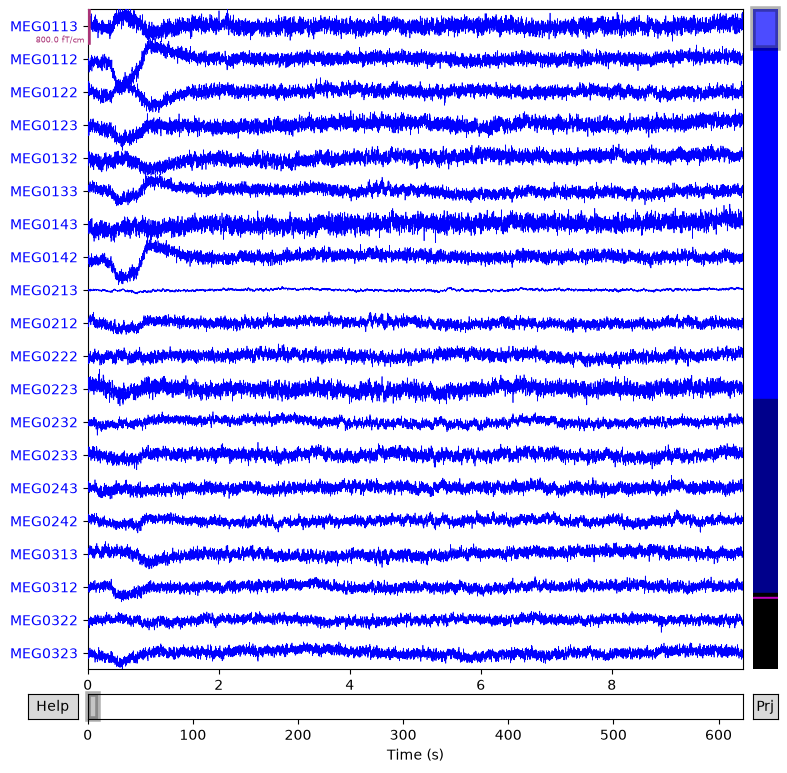

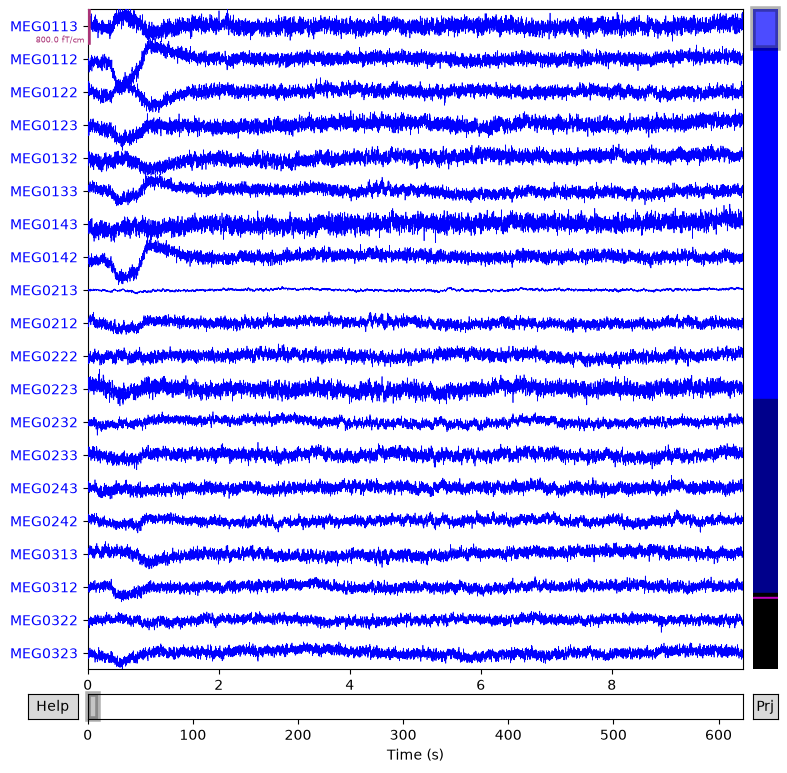

In [8]:
# Plot de Gradiometers
raw.plot()

## Session-level MEG files (calibration, crosstalk, coordinate system)

Besides the per-run files, each session has shared MEG files: a fine-calibration
`.dat` file, a crosstalk-compensation `.fif` file, and a `coordsystem.json`
describing the head/device coordinate frames.


In [9]:
def shorten(value, limit=140):
    text = str(value).replace('\n', ' ')
    return text if len(text) <= limit else text[:limit - 1] + '…'


def file_preview(path):
    size = path.stat().st_size

    if path.suffix.lower() in {'.tsv', '.csv'}:
        separator = '\t' if path.suffix.lower() == '.tsv' else ','
        frame = pd.read_csv(path, sep=separator, nrows=5)
        frame = frame.map(shorten)
        return frame.to_string(index=False).replace('\n', ' | ')

    if path.suffix.lower() == '.json':
        contents = json.dumps(json.loads(path.read_text()), ensure_ascii=False)
        return shorten(contents, 700)

    if path.name.endswith('.nii.gz'):
        with gzip.open(path, 'rb') as file:
            header = file.read(352)
        little_size = struct.unpack('<i', header[:4])[0]
        endian = '<' if little_size == 348 else '>'
        dimensions = struct.unpack(f'{endian}8h', header[40:56])
        voxel_sizes = struct.unpack(f'{endian}8f', header[76:108])
        return (f"NIfTI-1 dimensions={dimensions[1:dimensions[0] + 1]}, "
                f"voxel sizes (mm)={voxel_sizes[1:dimensions[0] + 1]}; "
                f"header bytes={header[:16].hex(' ')}")

    if path.suffix.lower() == '.wav':
        with wave.open(str(path), 'rb') as audio:
            channels_count = audio.getnchannels()
            sample_width = audio.getsampwidth()
            frames = audio.readframes(4)
            sample_format = {1: 'B', 2: 'h', 4: 'i'}.get(sample_width)
            samples = (
                struct.unpack('<' + sample_format * (len(frames) // sample_width), frames)
                if sample_format else frames.hex(' ')
            )
            return (f"WAV: {channels_count} channels, {audio.getframerate()} Hz, "
                    f"{audio.getnframes():,} frames, {sample_width} bytes/sample; "
                    f"first samples={samples}")

    if path.suffix.lower() in {'.fif', '.dat'}:
        with path.open('rb') as file:
            first_bytes = file.read(32)
        try:
            text = path.read_text(encoding='utf-8')
            if '\x00' not in text:
                return ' | '.join(shorten(line, 160) for line in text.splitlines()[:5])
        except UnicodeError:
            pass
        return f"Binary data ({size:,} bytes); first 32 bytes={first_bytes.hex(' ')}"

    try:
        lines = path.read_text(encoding='utf-8').splitlines()
        preview = ' | '.join(shorten(line, 180) for line in lines[:5])
        return preview + (f" | … ({len(lines) - 5} more lines)" if len(lines) > 5 else '')
    except UnicodeError:
        with path.open('rb') as file:
            first_bytes = file.read(32)
        return f"Binary data ({size:,} bytes); first 32 bytes={first_bytes.hex(' ')}"


def preview_frame(paths):
    rows = []
    for path in paths:
        try:
            preview = file_preview(path)
        except Exception as error:
            preview = f"Preview error: {type(error).__name__}: {error}"
        rows.append({
            'file': path.relative_to(LISTEN_DIR).as_posix(),
            'size (bytes)': path.stat().st_size,
            'head / content preview': preview,
        })
    return pd.DataFrame(rows)


session_meg_files = [
    meg_dir / f"{subjects[0]}_ses-01_acq-calibration_meg.dat",
    meg_dir / f"{subjects[0]}_ses-01_acq-crosstalk_meg.fif",
    meg_dir / f"{subjects[0]}_ses-01_coordsystem.json",
]
with pd.option_context('display.max_colwidth', 1000, 'display.width', None):
    display(preview_frame(session_meg_files))

,file,size (bytes),head / content preview
0,sub-01/ses-01/meg/sub-01_ses-01_acq-calibration_meg.dat,39101,113\t-0.106600 0.046400 -0.060400 -0.022984 0.007676 -0.999706 -0.190700 -0.981654 -0.003225 -0.981268 0.191890 0.016455 -0.005871 | 112\t-0.106600 0.046400 -0.060400 -0.190700 -0.981654 -0.003225 0.022984 -0.007676 0.999706 -0.981268 0.191890 0.016455 0.001164 | 111\t-0.106600 0.046400 -0.060400 -0.022984 0.007676 -0.999706 -0.190700 -0.981654 -0.003225 -0.981268 0.191890 0.016455 1.001059 | 122\t-0.102000 0.063100 -0.025600 0.001592 0.004517 -0.999984 -0.265233 -0.964173 -0.004786 -0.963466 0.267827 -0.000344 -0.003354 | 123\t-0.102000 0.063100 -0.025600 -0.265233 -0.964173 -0.004786 -0.001592 -0.004517 0.999984 -0.963466 0.267827 -0.000344 -0.004871
1,sub-01/ses-01/meg/sub-01_ses-01_acq-crosstalk_meg.fif,47399,"Binary data (47,399 bytes); first 32 bytes=00 00 00 64 00 00 00 1f 00 00 00 14 00 00 00 00 00 01 00 01 00 10 83 f9 57 d7 00 00 3a f2 62 6b"
2,sub-01/ses-01/meg/sub-01_ses-01_coordsystem.json,2160,"{""MEGCoordinateSystem"": ""ElektaNeuromag"", ""MEGCoordinateUnits"": ""m"", ""MEGCoordinateSystemDescription"": ""RAS orientation and the origin between the ears"", ""HeadCoilCoordinates"": {""NAS"": [0.0, 0.10237890481948853, -1.4901161193847656e-08], ""LPA"": [-0.06835231930017471, 0.0, -1.862645149230957e-08], ""RPA"": [0.0655471459031105, 0.0, -1.862645149230957e-08], ""coil1"": [-0.07135564088821411, -0.01904696226119995, 0.013616299256682396], ""coil2"": [-0.04731733351945877, 0.09483689069747925, 0.042590316385030746], ""coil3"": [0.06833426654338837, -0.023957818746566772, 0.010229412466287613], ""coil4"": [0.04964799806475639, 0.09100332856178284, 0.04081704095005989]}, ""HeadCoilCoordinateSystem"": ""ElektaNeu…"


## Anatomical data (subject T1w MRI)

The subject's `anat/` folder holds the T1-weighted structural MRI used for
coregistration/source analysis, alongside its BIDS JSON sidecar.


In [10]:
anat_files = sorted(p for p in anat_dir.iterdir() if p.is_file())
with pd.option_context('display.max_colwidth', 1000, 'display.width', None):
    display(preview_frame(anat_files))

,file,size (bytes),head / content preview
0,sub-01/ses-01/anat/sub-01_ses-01_T1w.json,1894,"{""Modality"": ""MR"", ""MagneticFieldStrength"": 3, ""ImagingFrequency"": 123.261, ""Manufacturer"": ""Siemens"", ""ManufacturersModelName"": ""Prisma_fit"", ""InstitutionName"": ""NeuroSpin"", ""InstitutionalDepartmentName"": ""Department"", ""InstitutionAddress"": ""Street N306,SACLAY,IdF,FR,91400"", ""DeviceSerialNumber"": ""67069"", ""StationName"": ""MRCTRIO"", ""BodyPartExamined"": ""BRAIN"", ""PatientPosition"": ""HFS"", ""ProcedureStepDescription"": ""Protocoles^Anat_MEG"", ""SoftwareVersions"": ""syngo MR E11"", ""MRAcquisitionType"": ""3D"", ""SeriesDescription"": ""mprage_sag_T1_160sl"", ""ProtocolName"": ""mprage_sag_T1_160sl"", ""ScanningSequence"": ""GR\\IR"", ""SequenceVariant"": ""SK\\SP\\MP\\OSP"", ""ScanOptions"": ""IR\\PFP"", ""SequenceName"": ""*t…"
1,sub-01/ses-01/anat/sub-01_ses-01_T1w.nii.gz,9750694,"NIfTI-1 dimensions=(160, 240, 256), voxel sizes (mm)=(1.0, 1.0, 1.0); header bytes=5c 01 00 00 00 00 00 00 00 00 00 00 00 00 00 00"
